# Customer Churn Prediction & Retention Strategy
**Author:** Sazia Parween · Data Analyst

**Business problem:** a telecom company loses **26.5% of its customers** — about **30% of monthly revenue** walks out the door. The retention team has budget for discounts and offers, but doesn't know *who* to target or *what* to offer.

**Goal:** predict which customers will churn, explain *why*, and decide who to contact so the retention campaign makes money.

Data: [IBM Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d) — 7,043 customers, 21 columns.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import pandas as pd
from IPython.display import Image, display
raw = pd.read_csv('../data/raw/telco_customer_churn.csv')
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data quality
`TotalCharges` looks numeric but is stored as text — 11 rows contain a blank space. Every one of them has `tenure = 0`, i.e. a brand-new customer who hasn't been billed yet, so the correct fix is 0, not the column mean.

In [2]:
print(raw.dtypes['TotalCharges'])
blank = raw['TotalCharges'].str.strip() == ''
raw.loc[blank, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

str


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [3]:
import clean
df = clean.main()

Raw rows x columns                                                     7,043 x 21
Duplicate customerID                                                            0
Blank TotalCharges (stored as text)                                            11
-> filled with 0 (tenure = 0, not yet billed)                                  11
'No internet/phone service' values collapsed to 'No'                        9,838
Customers where TotalCharges deviates >25% from tenure x monthly               27
Engineered features added                                                       7
Clean rows x columns                                                   7,043 x 28


## 2. SQL analysis
The clean table is loaded into SQLite and analysed with SQL (`sql/churn_queries.sql`).

In [4]:
import sqlite3, contextlib, io
import sql_analysis
from sql_analysis import load_queries, SQL_FILE, DB
with contextlib.redirect_stdout(io.StringIO()):
    sql_analysis.main()            # runs every query, saves reports/sql_results.md
queries = dict(load_queries(SQL_FILE))
con = sqlite3.connect(DB)
for q in ['1. Churn KPI snapshot', '2. Churn by contract type',
          '7. Highest-risk segment: combine the 3 strongest drivers (CTE)']:
    print(q); display(pd.read_sql_query(queries[q], con))

1. Churn KPI snapshot


,customers,churned,churn_rate_pct,total_mrr,lost_mrr,lost_mrr_pct
0,7043,1869,26.5,456117.0,139131.0,30.5


2. Churn by contract type


,Contract,customers,churn_rate_pct,avg_monthly_charge,annual_revenue_lost
0,Month-to-month,3875,42.7,66.40,1450165.0
1,One year,1473,11.3,65.05,169421.0
2,Two year,1695,2.8,60.77,49984.0


7. Highest-risk segment: combine the 3 strongest drivers (CTE)


,contract_type,tenure_type,internet,customers,churn_rate_pct,annual_revenue_lost,risk_rank
0,M2M,New (<=12m),Fiber,916,70.2,638140.0,1
1,M2M,Established,Fiber,1212,42.8,567644.0,2
2,M2M,New (<=12m),Other,1078,35.3,181478.0,3
3,M2M,Established,Other,669,16.7,62903.0,4
4,Term,Established,Fiber,961,13.8,163403.0,5
5,Term,New (<=12m),Other,185,5.9,5420.0,6
6,Term,Established,Other,2015,3.4,48169.0,7


**Insight:** new month-to-month fiber customers churn at **70%** — that single segment loses ~$640k of annual revenue.

## 3. Exploratory analysis

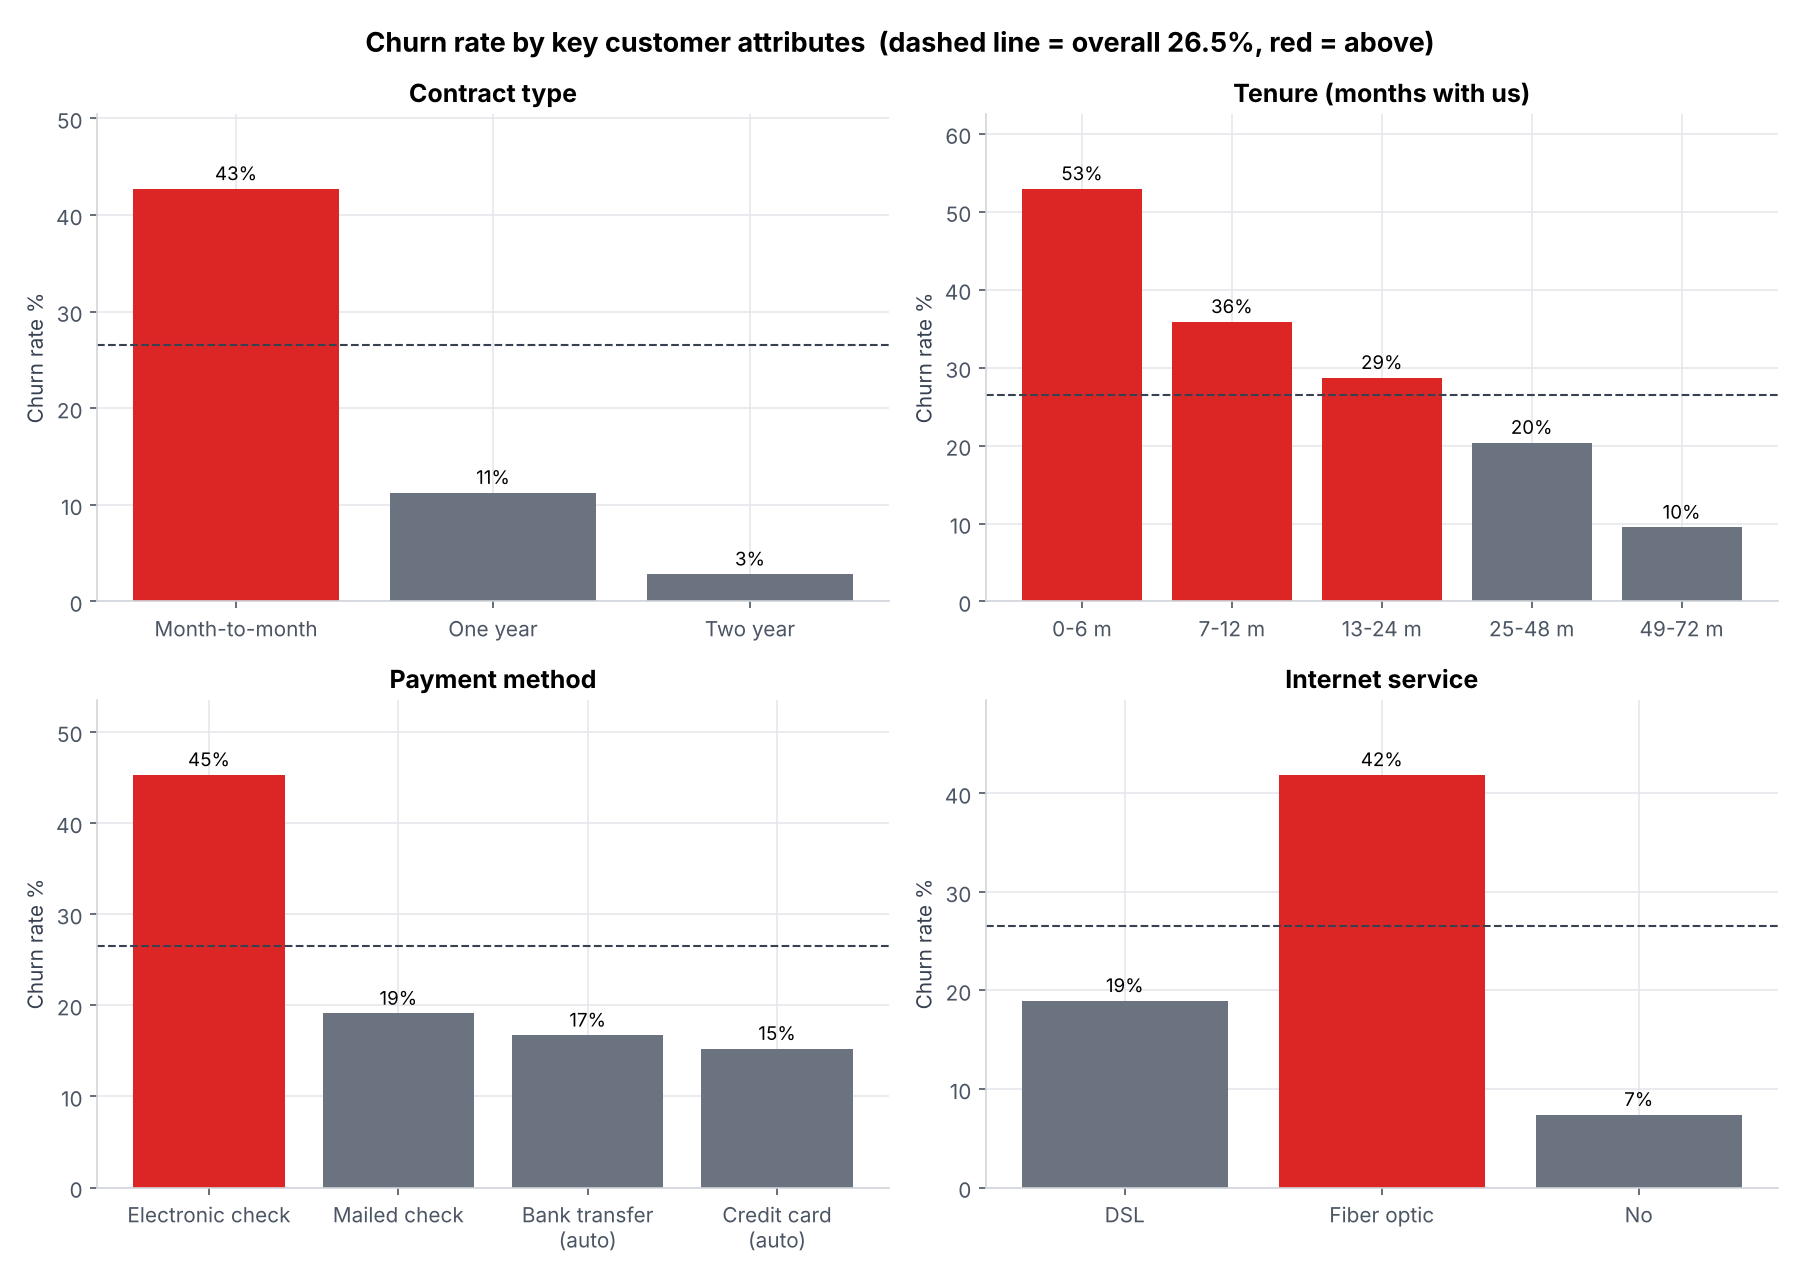

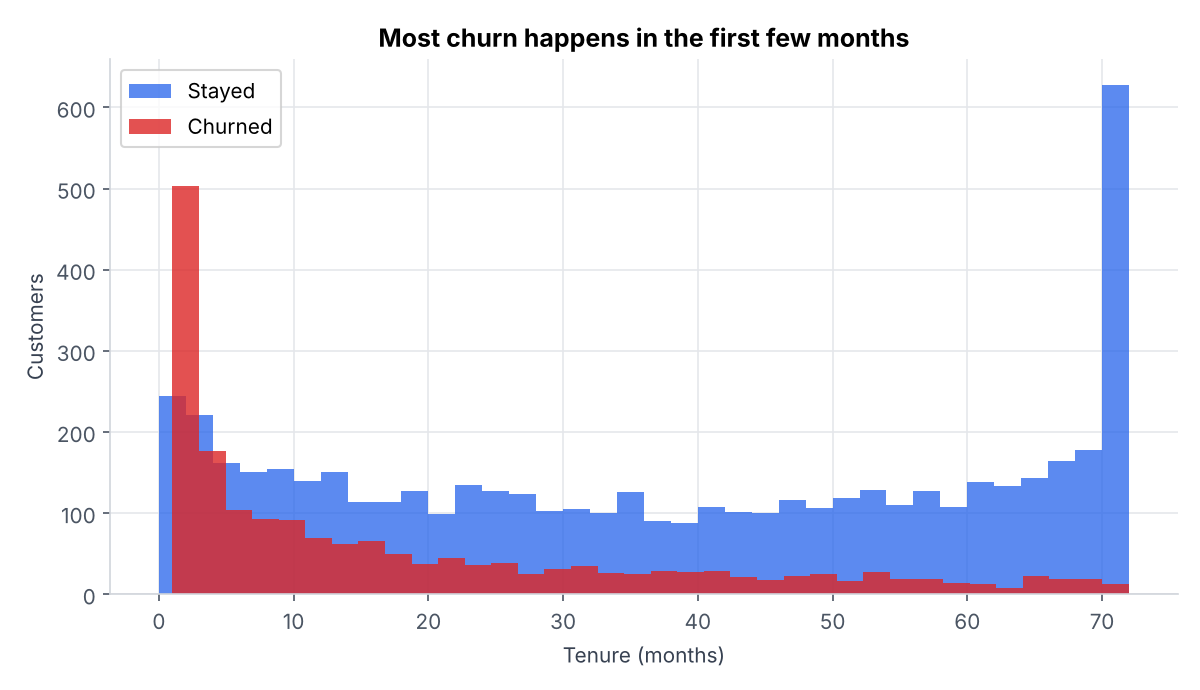

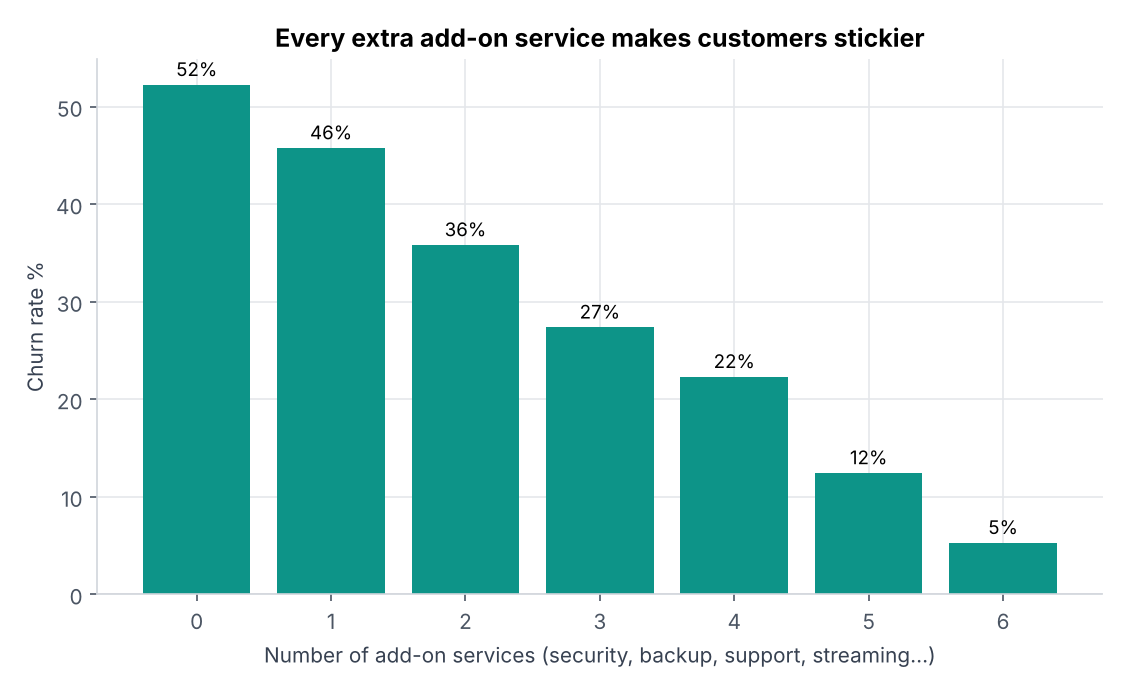

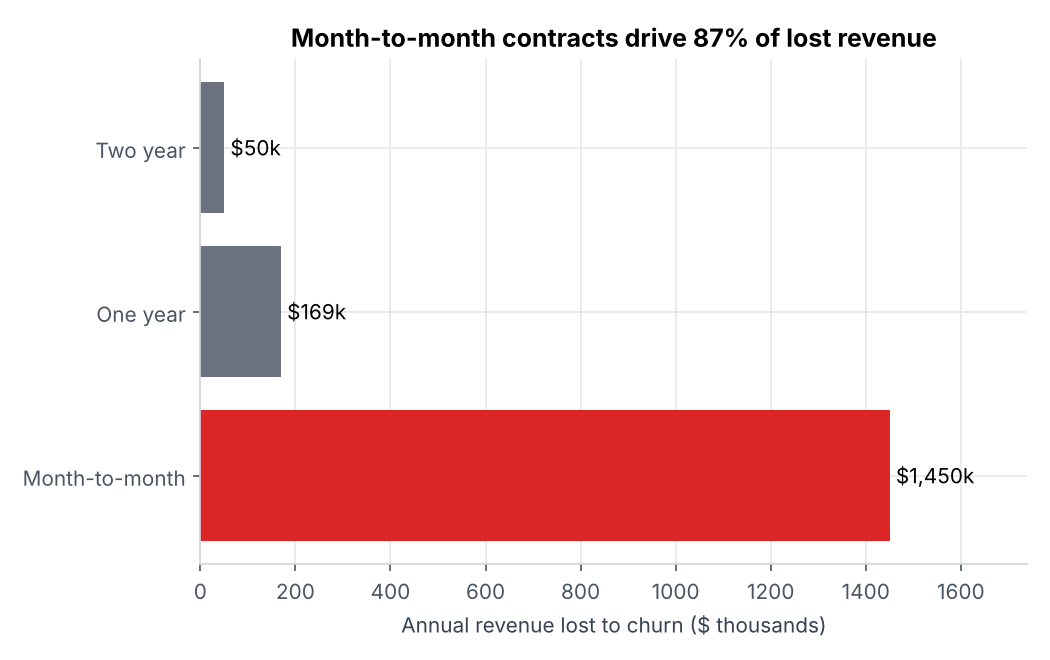

In [5]:
for f in ['eda_churn_drivers', 'eda_tenure_distribution', 'eda_addons', 'eda_revenue_lost']:
    display(Image(f'../reports/figures/{f}.png', width=820))

## 4. Modelling
- 80/20 stratified split; the 20% test set is used **once**, at the very end.
- Three models compared with 5-fold cross-validation on the training set.
- No class re-weighting: probabilities stay honest, and the 26/74 imbalance is handled by choosing the decision threshold.

In [6]:
import contextlib, io, train
with contextlib.redirect_stdout(io.StringIO()):
    m = train.main()
pd.DataFrame(m['model_comparison']).T

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,cv_roc_auc,cv_pr_auc,test_roc_auc
Logistic Regression,0.8449,0.6556,0.8421
Random Forest,0.8462,0.6559,0.8459
XGBoost,0.8449,0.6561,0.8441


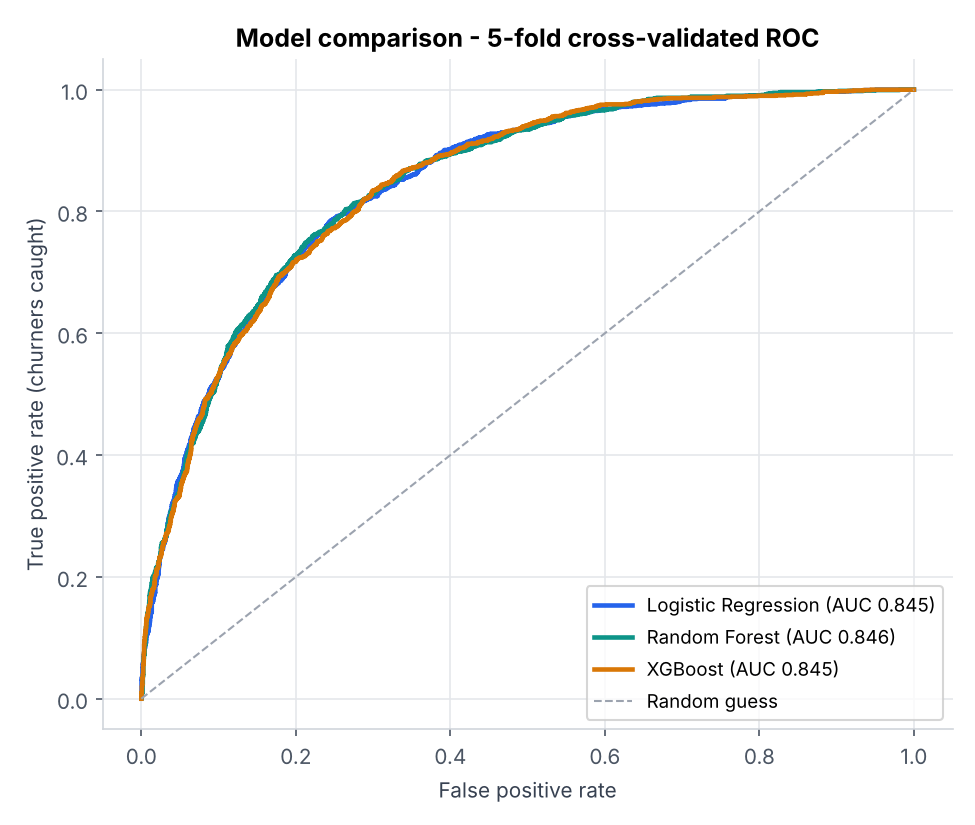

In [7]:
display(Image('../reports/figures/model_roc_comparison.png', width=520))

## 5. Turning predictions into money
A retention offer costs money, so contacting *everyone* isn't free. Assumptions (editable in `src/train.py`):
- offer cost **$60** per customer contacted
- the offer saves **30%** of would-be churners
- a saved customer keeps paying for **12 months**

The threshold is chosen to maximise net value on cross-validated predictions, then checked on the test set.

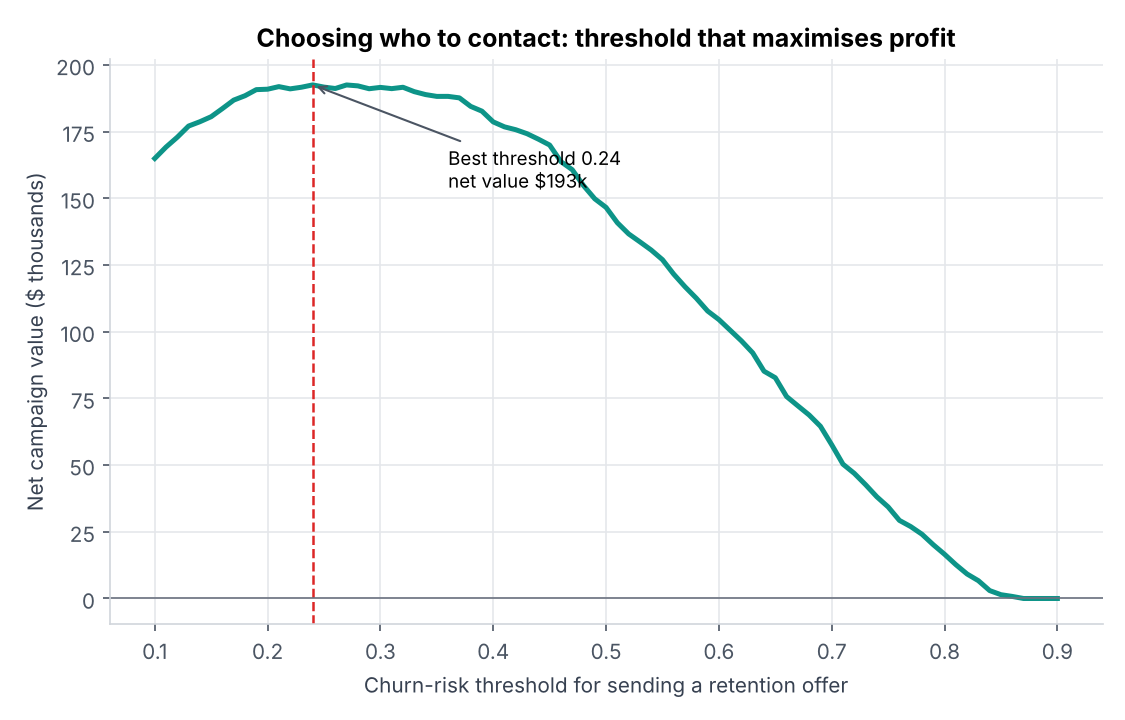

,AI-targeted campaign,Contact everyone
threshold,0.24,0.5
contacted,621.00,1409.0
churners_reached,310.00,374.0
saved_revenue,82807.00,97974.0
campaign_cost,37260.00,84540.0
net_value,45547.00,13434.0


In [8]:
display(Image('../reports/figures/profit_vs_threshold.png', width=640))
pd.DataFrame({'AI-targeted campaign': m['campaign_on_test_set'],
              'Contact everyone': m['contact_everyone_on_test_set']})

## 6. Explainability (SHAP)

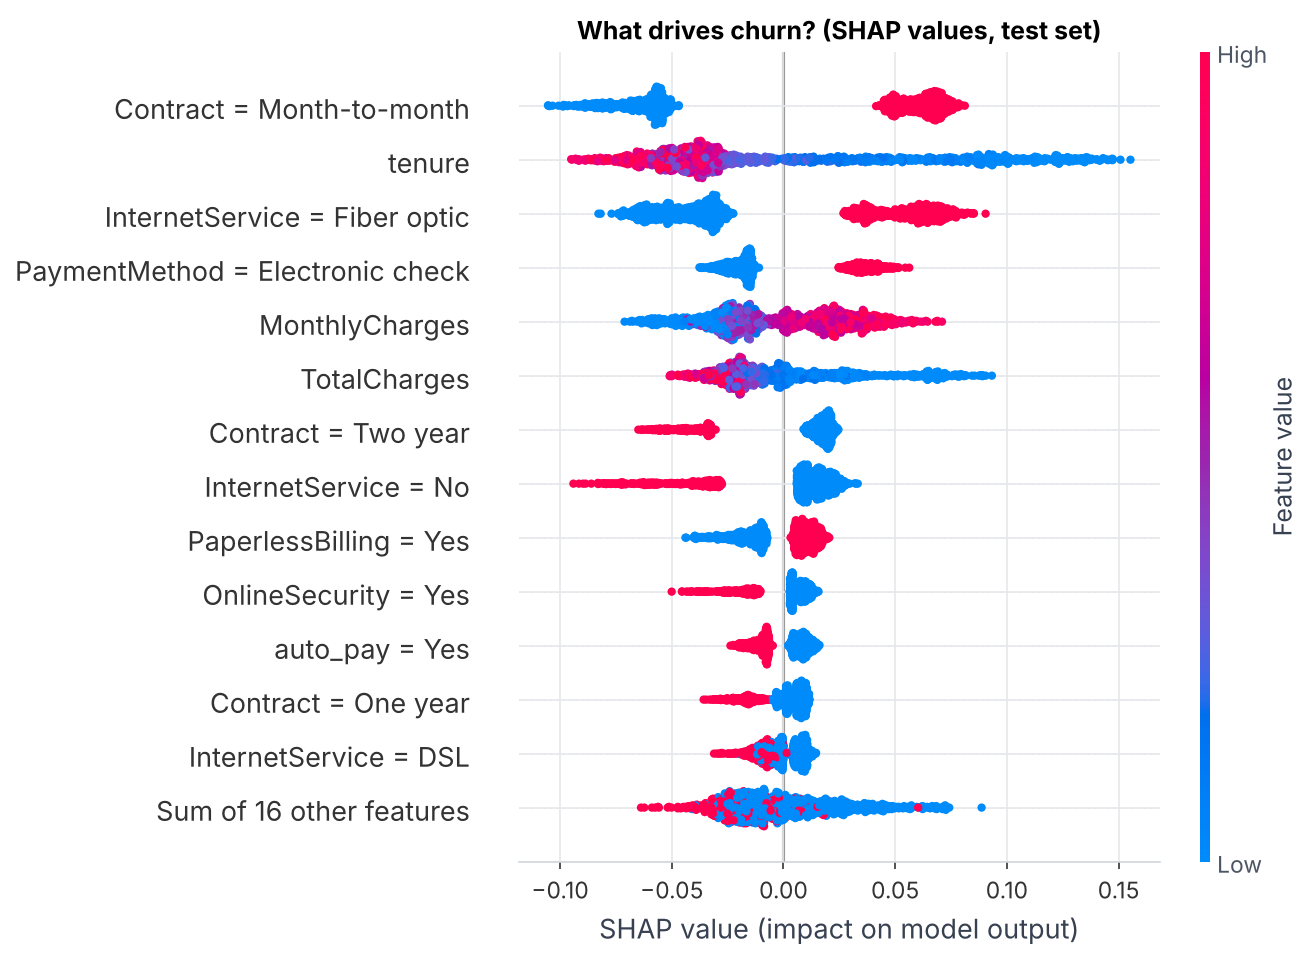

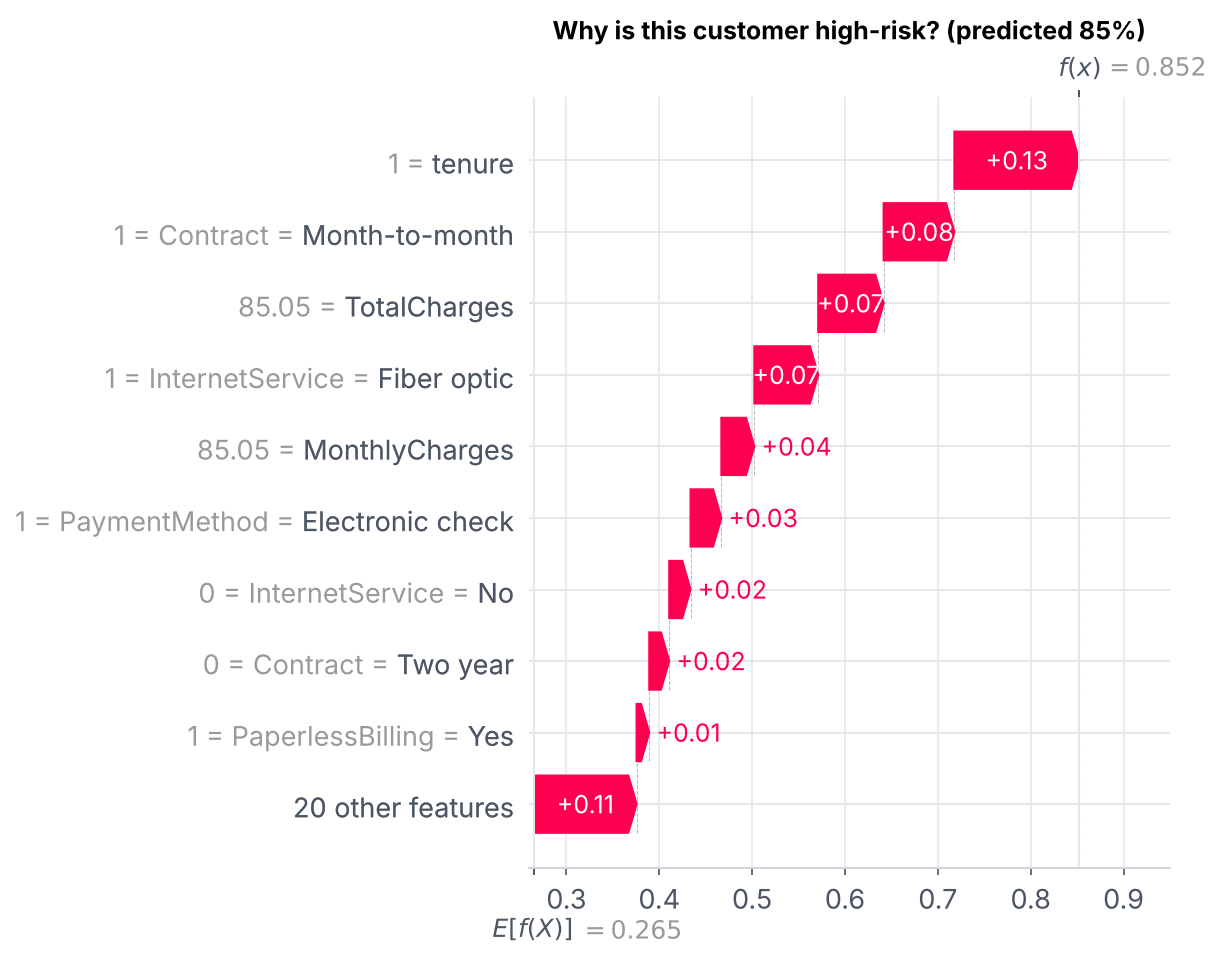

In [9]:
display(Image('../reports/figures/shap_summary.png', width=720))
display(Image('../reports/figures/shap_single_customer.png', width=620))

## 7. Score a new customer

In [10]:
from predict import score_customer
score_customer({'tenure': 2, 'Contract': 'Month-to-month', 'InternetService': 'Fiber optic',
                'PaymentMethod': 'Electronic check', 'MonthlyCharges': 89.5})

{'churn_probability': 0.726,
 'risk_band': 'High',
 'annual_revenue_at_risk': np.float64(779.66),
 'recommended_action': 'Onboarding call + first-3-months welcome discount',
 'top_reasons': [{'feature': 'tenure = 2',
   'impact': 0.105,
   'direction': 'raises risk'},
  {'feature': 'Contract = Month-to-month',
   'impact': 0.067,
   'direction': 'raises risk'},
  {'feature': 'InternetService = Fiber optic',
   'impact': 0.065,
   'direction': 'raises risk'},
  {'feature': 'TotalCharges = 179',
   'impact': 0.05,
   'direction': 'raises risk'},
  {'feature': 'MonthlyCharges = 89.5',
   'impact': 0.04,
   'direction': 'raises risk'}]}

## 8. Retention list for the business

In [11]:
risk = pd.read_csv('../reports/at_risk_customers.csv')
display(risk.groupby('risk_band').agg(customers=('customerID','count'),
        revenue_at_risk=('annual_revenue_at_risk','sum')).round(0))
risk.head(10)

,customers,revenue_at_risk
risk_band,,
High,485,271069.0
Low,3586,231016.0
Medium,1103,332636.0


,customerID,tenure,Contract,InternetService,PaymentMethod,TechSupport,MonthlyCharges,charge_increase,churn_risk,risk_band,recommended_action,annual_revenue_at_risk
0,4912-PIGUY,1,Month-to-month,Fiber optic,Electronic check,No,84.60,0.0,0.857,High,Onboarding call + first-3-months welcome discount,870.03
1,7439-DKZTW,1,Month-to-month,Fiber optic,Electronic check,No,80.55,0.0,0.857,High,Onboarding call + first-3-months welcome discount,828.38
2,7577-SWIFR,1,Month-to-month,Fiber optic,Electronic check,No,89.25,0.0,0.850,High,Onboarding call + first-3-months welcome discount,910.35
3,0021-IKXGC,1,Month-to-month,Fiber optic,Electronic check,No,72.10,0.0,0.847,High,Onboarding call + first-3-months welcome discount,732.82
4,1452-VOQCH,1,Month-to-month,Fiber optic,Electronic check,No,75.10,0.0,0.845,High,Onboarding call + first-3-months welcome discount,761.51
5,5542-TBBWB,1,Month-to-month,Fiber optic,Electronic check,No,69.90,0.0,0.843,High,Onboarding call + first-3-months welcome discount,707.11
6,3878-AVSOQ,1,Month-to-month,Fiber optic,Electronic check,No,71.25,0.0,0.838,High,Onboarding call + first-3-months welcome discount,716.49
7,4273-MBHYA,1,Month-to-month,Fiber optic,Electronic check,No,89.35,0.0,0.835,High,Onboarding call + first-3-months welcome discount,895.29
8,9603-OAIHC,1,Month-to-month,Fiber optic,Electronic check,No,70.05,0.0,0.823,High,Onboarding call + first-3-months welcome discount,691.81
9,2254-DLXRI,1,Month-to-month,Fiber optic,Mailed check,No,79.15,0.0,0.819,High,Onboarding call + first-3-months welcome discount,777.89


## 9. Recommendations
1. **Convert month-to-month customers to annual contracts** — they are 87% of lost revenue. Offer a 10–15% discount for a 1-year commitment to high-risk M2M customers.
2. **Fix the first 6 months:** customers in their first 6 months churn at 53% → onboarding call + welcome discount.
3. **Bundle Tech Support with fiber:** fiber customers without tech support churn at 49% vs 23% with it.
4. **Move customers off electronic check** to auto-pay (45% vs ~15–17% churn) with a small one-time credit.
5. **Target, don't blanket:** the model-targeted campaign returns ~3.4× the net value of contacting everyone.

*Limitations:* this is a single snapshot (no time dimension), the offer cost & success rate are assumptions to be validated with an A/B test, and churn drivers are associations, not proven causes.